In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import cmocean
import pandas as pd
import scipy.signal as signal
from pathlib import Path
import pinner2026_jpo_code
import pinner2026_jpo_code.plots

INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"
DERIVED_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "derived"
FIGURE_DIR: Path = pinner2026_jpo_code.FIGURE_DIR

ONE_COLUMN_WIDTH = pinner2026_jpo_code.plots.ONE_COLUMN_WIDTH

Text(-0.08, -0.08, 'depths / m')

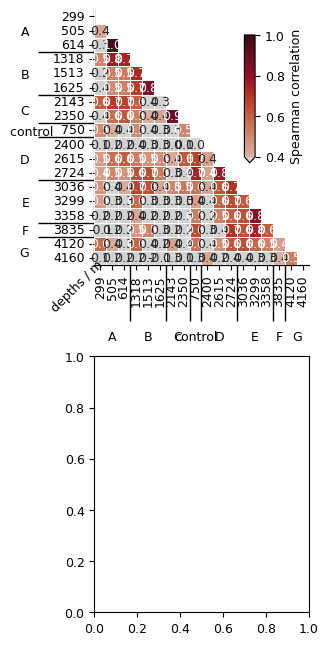

In [3]:
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})


def smooth(array, length):
    window = signal.windows.hann(length)  # construct Hanning window
    # smooth by convolving speed with window
    smoothed = signal.convolve(array, window, mode="same") / np.sum(window)
    return smoothed


hke = pd.read_csv(INTERIM_DATA_DIR / "HKE.csv", index_col=0, header=[0, 1])
hke.index = pd.to_datetime(hke.index).floor("D")

# to focus only on the seasonal variability
# we smooth over 5 data points
smoothed_hke = hke.apply(smooth, args=(5,))


corr = smoothed_hke.corr(method="spearman")
# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
fig, ax = plt.subplots(
    nrows=2, figsize=(ONE_COLUMN_WIDTH, 2 * ONE_COLUMN_WIDTH), layout="constrained"
)

# --------------------- ax 0 --------------------------------------

# Generate a custom diverging colormap
cmap = cmocean.cm.amp
clipped_cmap = cmocean.tools.crop_by_percent(cmap, 20, which="min", N=None)
clipped_cmap.set_extremes(under="lightgray")
clipped_correlation = 0.4

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(
    data=corr,
    mask=mask,
    cmap=clipped_cmap,
    vmax=1,
    vmin=clipped_correlation,
    # center=0,
    linewidths=0.5,
    cbar=False,
    cbar_kws={"shrink": 0.4},  # , set_frame_on:True},
    annot=True,
    annot_kws={"fontsize": 9},
    fmt=".1f",
    ax=ax[0],
    xticklabels=corr.index.get_level_values(1),
    yticklabels=corr.index.get_level_values(1),
)

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

cax = ax[0].inset_axes([0.7, 0.4, 0.05, 0.5])
norm = mpl.colors.Normalize(vmin=clipped_correlation, vmax=1)
fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=clipped_cmap),
    extend="min",
    cax=cax,
    orientation="vertical",
    label="Spearman correlation",
    shrink=0.1,
)

ax[0].set(xlabel="", ylabel="")
# label the classes:
sec = ax[0].secondary_yaxis(location=0)
labels = [f"{s:{' '}<16}" for s in pd.unique(corr.index.get_level_values(0))]
sec.set_yticks([1.5, 4.5, 7, 8.5, 10.5, 13.5, 15.5, 17], labels=labels)
sec.tick_params("y", length=0)
# lines between the classes:
sec2 = ax[0].secondary_yaxis(location=0)
sec2.set_yticks([3, 6, 8, 9, 12, 15, 16], labels=[])
sec2.tick_params("y", length=40, width=1)

sec = ax[0].secondary_xaxis(location=0)
newline = "\n"
labels = [f"{4 * newline}{mooring}" for mooring in pd.unique(corr.index.get_level_values(0))]
# for i,label in enumerate(labels.copy()):
#     if "control" in label:
#         labels[i] = "\n"+label
sec.set_xticks([1.5, 4.5, 7, 8.5, 10.5, 13.5, 15.5, 17], labels=labels)
sec.tick_params("x", length=0)
# lines between the classes:
sec2 = ax[0].secondary_xaxis(location=0)
sec2.set_xticks([3, 6, 8, 9, 12, 15, 16], labels=[])
sec2.tick_params("x", length=40, width=1)
ax[0].tick_params(axis="x", labelrotation=90)
# ax[0].set_title("Pairwise Correlation")
ax[0].text(
    -0.08, -0.08, "depths / m", transform=ax[0].transAxes, ha="center", va="center", rotation=45
)

# --------------------- ax 1 --------------------------------------


# --------------------- saving --------------------------------------

# fig.savefig(FIGURE_DIR / "f04_HKE_pair_correlation.pdf")
# plt.show()

In [12]:
masked_corr_df = corr.where(mask)
# masked_corr_df[masked_corr_df==1] = np.nan
masked_corr_df[np.eye(len(masked_corr_df), dtype=bool) == 1] = np.nan
masked_corr_df

A                             B                             C  \
             299       505       614      1318      1513      1625      2143   
A       299  NaN  0.430626  0.338024  0.512432  0.186322  0.360442  0.608884   
        505  NaN       NaN  0.966231  0.768727  0.518318  0.494571  0.692053   
        614  NaN       NaN       NaN  0.745490  0.535113  0.524587  0.676324   
B       1318 NaN       NaN       NaN       NaN  0.728439  0.681668  0.601711   
        1513 NaN       NaN       NaN       NaN       NaN  0.841848  0.374660   
        1625 NaN       NaN       NaN       NaN       NaN       NaN  0.345992   
C       2143 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
        2350 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
control 750  NaN       NaN       NaN       NaN       NaN       NaN       NaN   
D       2400 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
        2615 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
        2724 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
E       3036 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
        3299 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
        3358 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
F       3835 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
G       4120 NaN       NaN       NaN       NaN       NaN       NaN       NaN   
        4160 NaN       NaN       NaN       NaN       NaN       NaN       NaN   

                         control         D                             E  \
                  2350       750      2400      2615      2724      3036   
A       299   0.368911  0.496491  0.105119  0.454066  0.447455  0.472070   
        505   0.569476  0.403238  0.203502  0.568602  0.503323  0.396334   
        614   0.618554  0.389169  0.235245  0.614251  0.473846  0.413047   
B       1318  0.520069  0.497012  0.382911  0.531058  0.637213  0.668949   
        1513  0.408207  0.378618  0.324721  0.480978  0.655803  0.641411   
        1625  0.434768  0.316285  0.291803  0.488961  0.537683  0.427551   
C       2143  0.888303  0.300211  0.021683  0.419925  0.274918  0.505743   
        2350       NaN  0.503186  0.114131  0.618335  0.363577  0.544025   
control 750        NaN       NaN  0.025078  0.670853  0.746996  0.557842   
D       2400       NaN       NaN       NaN  0.439157  0.446902  0.428927   
        2615       NaN       NaN       NaN       NaN  0.784038  0.627520   
        2724       NaN       NaN       NaN       NaN       NaN  0.705265   
E       3036       NaN       NaN       NaN       NaN       NaN       NaN   
        3299       NaN       NaN       NaN       NaN       NaN       NaN   
        3358       NaN       NaN       NaN       NaN       NaN       NaN   
F       3835       NaN       NaN       NaN       NaN       NaN       NaN   
G       4120       NaN       NaN       NaN       NaN       NaN       NaN   
        4160       NaN       NaN       NaN       NaN       NaN       NaN   

                                         F         G            
                  3299      3358      3835      4120      4160  
A       299   0.452577  0.213715 -0.051469  0.576464  0.106252  
        505   0.321230  0.208117  0.246712  0.418218  0.209747  
        614   0.261381  0.196616  0.201500  0.334180  0.156522  
B       1318  0.571538  0.427513  0.461388  0.590063  0.229862  
        1513  0.322133  0.236578  0.518732  0.370176  0.204843  
        1625  0.333944  0.188519  0.291535  0.207225 -0.062053  
C       2143  0.275024  0.235865  0.150563  0.438537  0.321753  
        2350  0.277949  0.266199  0.236876  0.369760  0.092516  
control 750   0.442023  0.529446  0.643089  0.563802  0.266874  
D       2400  0.362406  0.237470  0.344213  0.363705  0.427382  
        2615  0.599125  0.525250  0.356601  0.482249  0.177887  
        2724  0.656842  0.606182  0.709111  0.62

In [5]:
# Importing the great_circle module from the library
from geopy.distance import great_circle

In [6]:
mooring_info = pd.read_csv(
    INTERIM_DATA_DIR / "rcm_infos.csv", index_col=0
)  # .drop_duplicates(subset=["name"])
line = pd.DataFrame(mooring_info.iloc[[6]].to_dict(orient="list"), index=[6])
line["region"] = "control"
line["color"] = "white"
line["rounded depth"] = 750
line["rounded mab"] = np.nan
mooring_info = pd.concat([mooring_info.iloc[:6], line, mooring_info.iloc[6:]]).reset_index(
    drop=True
)

In [7]:
mooring_info["name"]

0     A
1     A
2     A
3     B
4     B
5     B
6     C
7     C
8     C
9     D
10    D
11    D
12    E
13    E
14    E
15    F
16    G
17    G
Name: name, dtype: str

In [8]:
coords = list(zip(mooring_info["lat"], mooring_info["lon"]))
n = len(coords)

dist = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        d = great_circle(coords[i], coords[j]).km
        dist[i, j] = dist[j, i] = d

dist_df = pd.DataFrame(dist, index=mooring_info["name"], columns=mooring_info["name"])

# same_mooring = np.zeros((n, n))
# for i in range(n):
#     for j in range(i + 1, n):
#         d = great_circle(coords[i], coords[j]).km
#         dist[i, j] = dist[j, i] = d

# dist_df = pd.DataFrame(dist, index=mooring_info["name"], columns=mooring_info["name"])

mooring_info["name"]

0     A
1     A
2     A
3     B
4     B
5     B
6     C
7     C
8     C
9     D
10    D
11    D
12    E
13    E
14    E
15    F
16    G
17    G
Name: name, dtype: str

In [9]:
assert dist_df.shape == corr.shape

dist_list = dist_df.to_numpy().flatten()
corr_list = masked_corr_df.to_numpy().flatten()

assert np.shape(dist_list) == np.shape(corr_list)

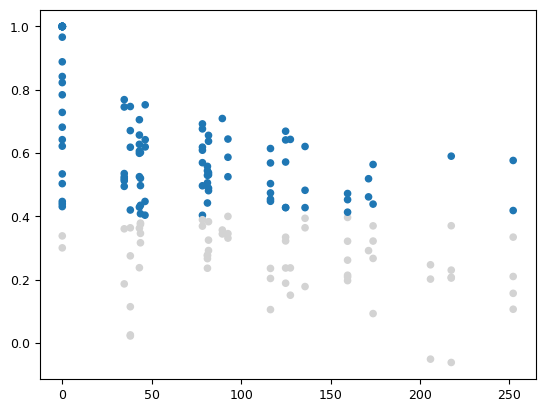

In [10]:
colors = np.where(corr_list <= 0.4, "lightgray", "tab:blue")
plt.scatter(dist_list, corr_list, s=20, c=colors)